# Part 3 — Descriptive analysis before unsupervised learning (archetypes)
### Equipo 5 · input: `data/g5_dataSample_v2_processed.csv` (output of `EDAbd2.ipynb`: nulls resolved, flags added)

The processed G5 file is a true panel (50,000 users × up to 19 months), so the **user-level feature table** is built by aggregating each
user's months. 

**What this file does NOT contain** (so these items of the brief cannot be computed from it): `accountLevel`, `creationFlowType`, age,
gender, tenure; payday / weekend / night shares; inter-transaction times; OXXO share of *spend* (only share of *transactions* exists).
Substitutes used, and flagged where they appear: month-to-month variability of activity for the temporal dimension; OXXO transaction
share for OXXO dependency; activity tier (tertiles of average spend) instead of `accountLevel` for the boxplots. The demographic profiling
section is therefore documented but not executed.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
sns.set_theme(style="whitegrid"); rng = np.random.default_rng(42)
pd.set_option("display.width", 250, "display.max_columns", 40, "display.max_rows", 100)

df = pd.read_csv("data/g5_dataSample_v2_processed.csv", parse_dates=["mes"])
df = df.sort_values(["userId", "mes"])
print(df.shape, df.userId.nunique(), df.mes.min().date(), df.mes.max().date())

(921438, 39) 50000 2025-01-01 2026-07-01


## 1. User-level feature table
Ratios are weighted by `tx_count_m` over *active* months (a ratio of nothing carries no weight).

In [2]:
def user_features(d):
    a = d[d.tx_count_m > 0]
    w = lambda col: (a[col] * a.tx_count_m).groupby(a.userId).sum() / a.tx_count_m.groupby(a.userId).sum()
    g = d.groupby("userId")
    f = pd.DataFrame(index=g.size().index)
    # OXXO dependency
    f["oxxo_tx_share"] = w("oxxo_tx_ratio_m")
    f["oxxo_ratio_trend"] = a.groupby("userId")["oxxo_ratio_delta_m"].mean()
    # merchant diversity
    f["merchant_entropy"] = a.groupby("userId")["merchant_entropy_m"].mean()
    f["unique_mcc"] = a.groupby("userId")["unique_mcc_m"].mean()
    # channel & card mix
    f["ecommerce_share"] = w("ecommerce_tx_ratio_m")
    f["virtual_card_share"] = w("virtual_card_ratio_m")
    f["intl_share"] = w("intl_tx_ratio_m")
    f["physical_other_share"] = (1 - w("oxxo_tx_ratio_m") - w("ecommerce_tx_ratio_m")).clip(lower=0)
    # temporal habits (proxies)
    f["active_month_share"] = g["tx_count_m"].apply(lambda s: (s > 0).mean())
    f["txcount_cv"] = g["tx_count_m"].agg(lambda s: s.std() / s.mean() if s.mean() > 0 else np.nan)
    f["tx_per_active_month"] = a.groupby("userId")["tx_count_m"].mean()
    # friction
    f["decline_rate"] = a.groupby("userId")["decline_ratio_m"].mean()
    f["pct_months_with_decline"] = g["had_decline_m"].mean()
    f["recovery_min"] = d[d.recovery_avg_min_m > 0].groupby("userId")["recovery_avg_min_m"].mean()
    # behaviour after a decline: change in next month's tx_count after a decline month vs after a clean month
    d = d.assign(next_tx=g["tx_count_m"].shift(-1))
    d["nxt_chg"] = d["next_tx"] - d["tx_count_m"]
    dec = d[d.had_decline_m & d.next_tx.notna()].groupby("userId")["nxt_chg"].mean()
    f["tx_change_after_decline"] = dec
    # intensity / funding
    f["avg_ticket"] = a.groupby("userId")["tx_amount_avg_m"].mean()
    f["monthly_spend"] = g["tx_amount_sum_m"].mean()
    f["cash_funding_ratio"] = d[~d.is_zero_funding_m].groupby("userId")["cash_funding_ratio_m"].mean()
    f["spei_amount"] = g["spei_amount_m"].mean()
    f["burn_ratio_med"] = d[(~d.is_zero_funding_m) & (d.spend_to_fund_ratio_m > 0)].groupby("userId")["spend_to_fund_ratio_m"].median()
    f["pct_months_zero_funding"] = g["is_zero_funding_m"].mean()
    return f

F = user_features(df)
DIMS = {"OXXO dependency": ["oxxo_tx_share", "oxxo_ratio_trend"],
        "Merchant diversity": ["merchant_entropy", "unique_mcc"],
        "Channel & card mix": ["ecommerce_share", "virtual_card_share", "intl_share", "physical_other_share"],
        "Temporal habits (proxy)": ["active_month_share", "txcount_cv", "tx_per_active_month"],
        "Friction": ["decline_rate", "pct_months_with_decline", "recovery_min", "tx_change_after_decline"],
        "Intensity / funding": ["avg_ticket", "monthly_spend", "cash_funding_ratio", "spei_amount", "burn_ratio_med", "pct_months_zero_funding"]}
FEATS = [x for v in DIMS.values() for x in v]; dim_of = {x: k for k, v in DIMS.items() for x in v}
print(F.shape); F.head()

(50000, 21)


,oxxo_tx_share,oxxo_ratio_trend,merchant_entropy,unique_mcc,ecommerce_share,virtual_card_share,intl_share,physical_other_share,active_month_share,txcount_cv,tx_per_active_month,decline_rate,pct_months_with_decline,recovery_min,tx_change_after_decline,avg_ticket,monthly_spend,cash_funding_ratio,spei_amount,burn_ratio_med,pct_months_zero_funding
userId,,,,,,,,,,,,,,,,,,,,,
SG5_000131a74409,0.467532,-0.041667,1.184773,2.166667,0.000000,0.000000,0.000000,0.532468,1.000000,0.503716,6.416667,0.140972,0.500000,4676.177778,2.200000,77.502104,501.187500,0.902236,212.484167,0.401465,0.166667
SG5_0003b71a5ba9,0.038462,0.006579,1.233388,4.157895,0.384615,0.000000,0.076923,0.576923,1.000000,0.654097,5.473684,0.411603,0.842105,15095.461378,-0.266667,186.133878,1042.160000,0.952526,94.796842,1.562795,0.473684
SG5_0003d78a5121,0.230216,0.000000,1.131442,3.583333,0.582734,0.000000,0.000000,0.187050,1.000000,1.075415,11.583333,0.039132,0.416667,647.050000,1.000000,306.098021,2113.634167,0.981253,66.716667,0.326472,0.250000
SG5_0003df2c9f4e,0.368421,0.018508,1.625902,4.736842,0.061404,0.061404,0.004386,0.570175,1.000000,0.756658,12.000000,0.240616,0.684211,10963.811066,-3.833333,157.437083,1966.561579,0.731218,767.845789,0.677029,0.315789
SG5_0005332ecd4e,0.099448,-0.002211,1.492589,5.071429,0.508287,0.458564,0.000000,0.392265,0.736842,1.214321,12.928571,0.097024,0.368421,9192.650794,-5.000000,439.515144,1548.156316,0.904840,265.481053,0.607896,0.473684


## 2. Descriptive statistics per feature
mean, median, std, P1/P25/P75/P99, skewness, kurtosis and % zeros (|x| ≤ 1e-3). Missing values are structural (e.g. users with no declines have no recovery time).

In [3]:
rows = []
for f in FEATS:
    x = F[f].dropna()
    rows.append(dict(dimension=dim_of[f], feature=f, pct_missing=100 * F[f].isna().mean(), mean=x.mean(), median=x.median(), std=x.std(),
                     P1=x.quantile(.01), P25=x.quantile(.25), P75=x.quantile(.75), P99=x.quantile(.99),
                     skewness=stats.skew(x), kurtosis=stats.kurtosis(x), pct_zeros=100 * (x.abs() <= 1e-3).mean(), n_unique=x.nunique()))
desc = pd.DataFrame(rows).set_index("feature"); desc.round(3)

,dimension,pct_missing,mean,median,std,P1,P25,P75,P99,skewness,kurtosis,pct_zeros,n_unique
feature,,,,,,,,,,,,,
oxxo_tx_share,OXXO dependency,0.000,0.107,0.046,0.157,0.000,0.000,0.141,0.769,2.531,7.780,25.872,17221
oxxo_ratio_trend,OXXO dependency,0.000,-0.002,0.000,0.024,-0.083,-0.004,0.000,0.071,-0.323,9.291,49.806,14967
merchant_entropy,Merchant diversity,0.000,1.192,1.123,0.621,0.050,0.735,1.587,2.857,0.544,0.089,0.712,48203
unique_mcc,Merchant diversity,0.000,3.908,3.250,2.433,1.000,2.200,4.929,12.368,1.788,4.832,0.000,1483
ecommerce_share,Channel & card mix,0.000,0.503,0.476,0.367,0.000,0.144,0.894,1.000,0.057,-1.513,7.932,18580
virtual_card_share,Channel & card mix,0.000,0.134,0.000,0.273,0.000,0.000,0.088,1.000,2.158,3.370,59.412,10780
intl_share,Channel & card mix,0.000,0.124,0.034,0.195,0.000,0.000,0.159,0.875,2.164,4.534,31.100,15292
physical_other_share,Channel & card mix,0.000,0.390,0.368,0.320,0.000,0.060,0.667,0.991,0.255,-1.282,17.042,20720
active_month_share,Temporal habits (proxy),0.000,0.853,0.895,0.135,0.579,0.737,1.000,1.000,-0.491,-1.074,0.000,37


## 3. Transformations
Rule: features with |skew| > 1 and non-negative support → winsorize at P99 then `log1p`; signed skewed features → winsorize at P1/P99; everything is z-scored before PCA/clustering. Missing values are median-filled for the modelling matrix (the missingness itself is informative, so `pct_missing` is kept in the readiness table).

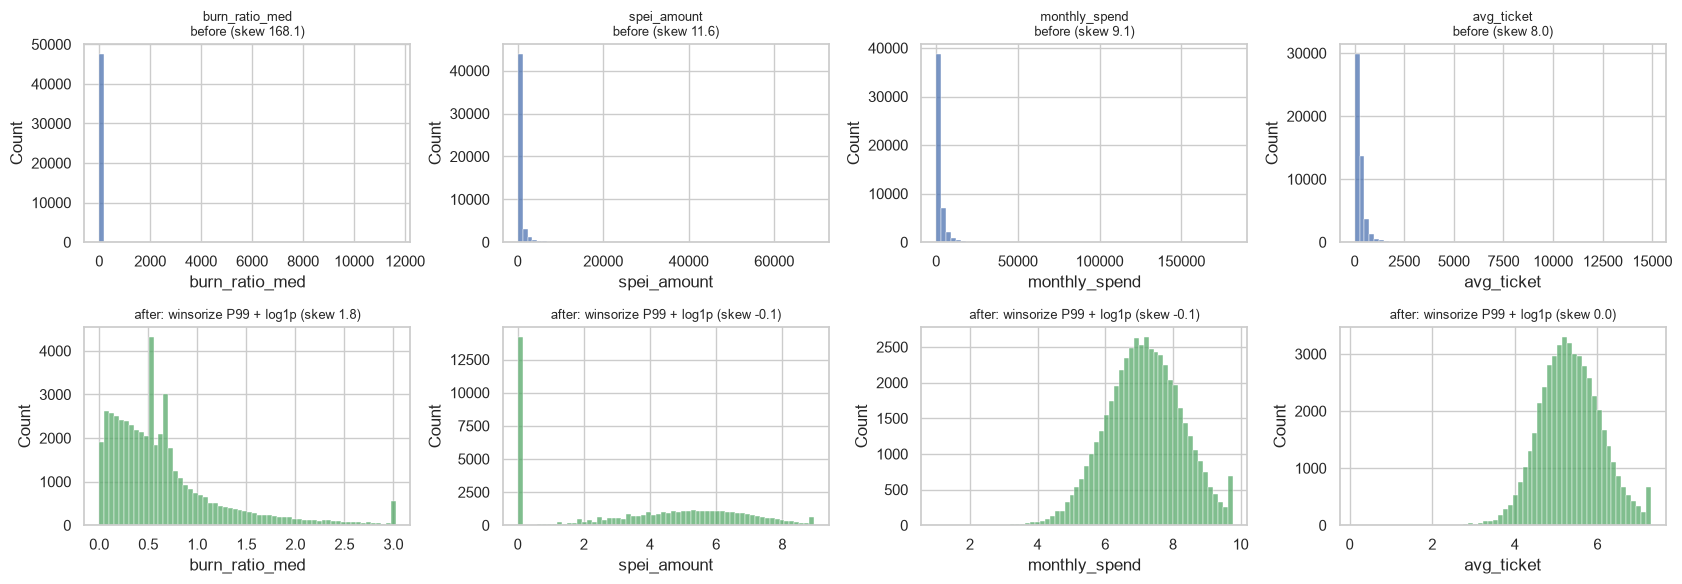

In [4]:
def transform(s, skew):
    if s.nunique() <= 2: return s, "none (binary)"
    if abs(skew) > 1:
        if s.min() >= 0: return np.log1p(s.clip(upper=s.quantile(.99))), "winsorize P99 + log1p"
        return s.clip(s.quantile(.01), s.quantile(.99)), "winsorize P1/P99"
    return s, "none"
T, tname = {}, {}
for f in FEATS:
    s = F[f].fillna(F[f].median()); T[f], tname[f] = transform(s, desc.loc[f, "skewness"])
T = pd.DataFrame(T); desc["transformation"] = pd.Series(tname); desc["skew_after"] = [stats.skew(T[f]) for f in desc.index]

top = desc.skewness.abs().sort_values(ascending=False).index[:4]
fig, ax = plt.subplots(2, 4, figsize=(17, 6))
for j, f in enumerate(top):
    sns.histplot(F[f].dropna(), bins=60, ax=ax[0, j], color="#4C72B0"); ax[0, j].set_title(f"{f}\nbefore (skew {desc.loc[f,'skewness']:.1f})", fontsize=9)
    sns.histplot(T[f], bins=60, ax=ax[1, j], color="#55A868"); ax[1, j].set_title(f"after: {tname[f]} (skew {desc.loc[f,'skew_after']:.1f})", fontsize=9)
plt.tight_layout(); plt.show()

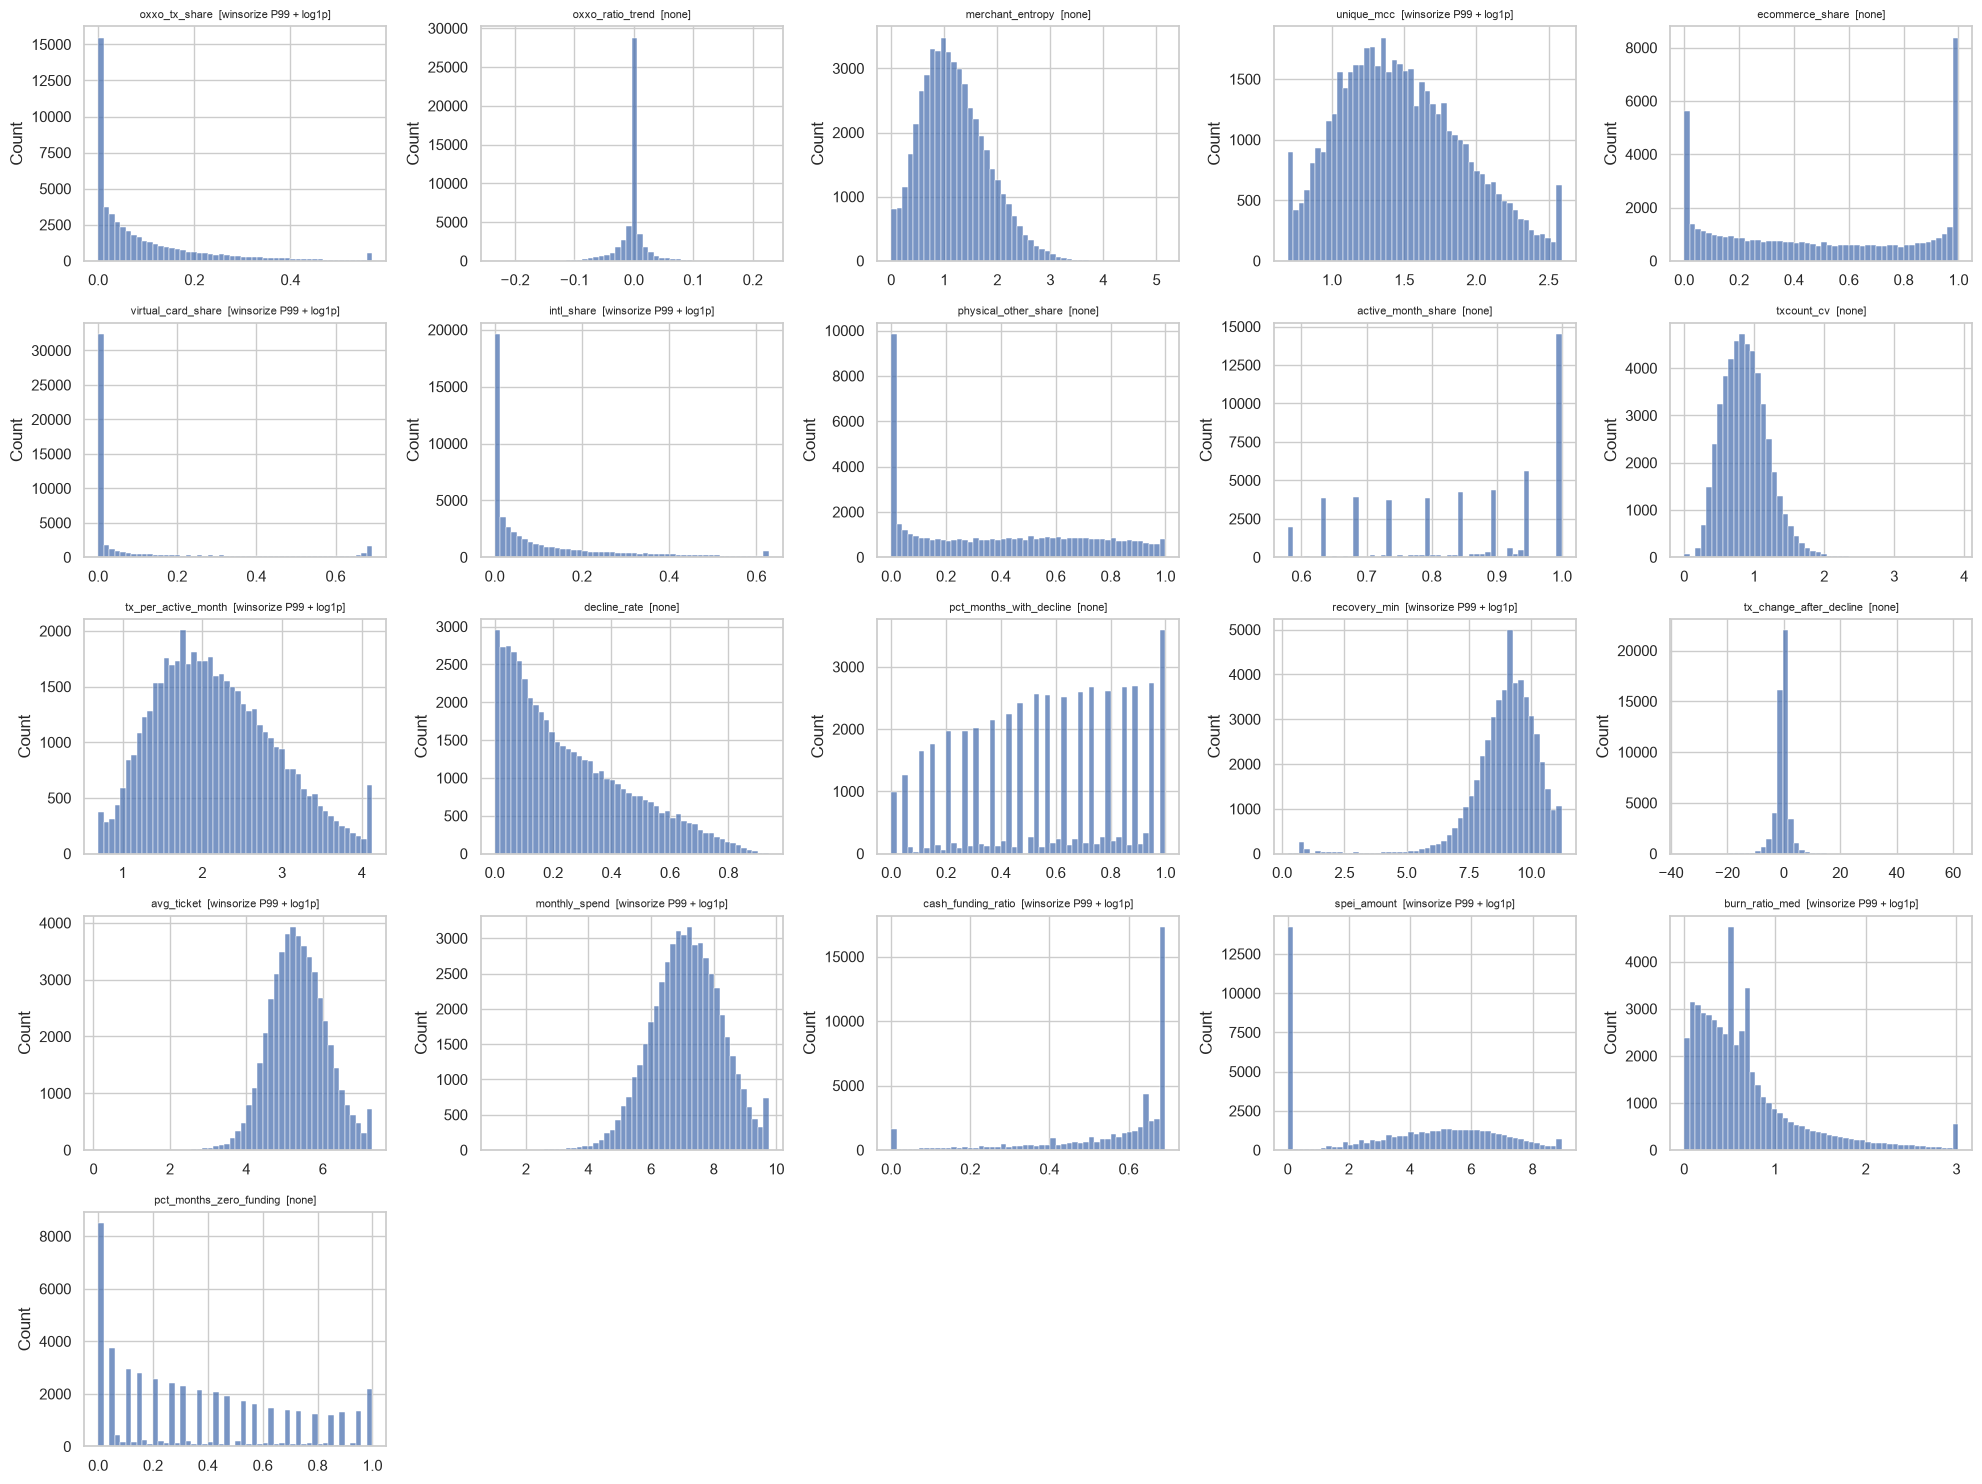

In [5]:
# histograms / densities of EVERY candidate feature (transformed)
n = len(FEATS); cols = 5; rws = int(np.ceil(n / cols))
fig, ax = plt.subplots(rws, cols, figsize=(20, 3 * rws))
for a, f in zip(ax.flat, FEATS):
    sns.histplot(T[f], bins=50, ax=a, color="#4C72B0"); a.set_title(f"{f}  [{tname[f]}]", fontsize=8); a.set_xlabel("")
for a in ax.flat[n:]: a.axis("off")
plt.tight_layout(); plt.show()

## 4. Near-zero variance / no-information features

In [6]:
nzv = desc[(desc.n_unique <= 2) | (desc["std"] < 1e-6) | (desc.pct_zeros > 95)][["pct_zeros", "std", "n_unique"]]
print("Candidates with no information (>95% zeros / constant):"); display(nzv)
print("Original panel columns, % exactly-zero or constant:")
for col in ["recovery_avg_min_m", "oxxo_ratio_delta_m", "tx_count_delta_m"]:
    print(f"  {col:22s} zeros={(df[col]==0).mean()*100:5.1f}%")

Candidates with no information (>95% zeros / constant):


,pct_zeros,std,n_unique
feature,,,


Original panel columns, % exactly-zero or constant:
  recovery_avg_min_m     zeros= 43.9%
  oxxo_ratio_delta_m     zeros= 67.6%
  tx_count_delta_m       zeros= 21.4%


No aggregated feature is constant or >95% zeros, so none is dropped for lack of information. Two columns of the *raw panel* need care:
`recovery_avg_min_m` is 43.9% zeros (the 0-fill for 'no decline' months) and `oxxo_ratio_delta_m` is 67.6% zeros, so they are only used
conditionally/aggregated (`recovery_min` = mean recovery time among declined months, `oxxo_ratio_trend` = mean delta). `spend_velocity_index_m` is not
in this file (it was ~99.9% zeros in the other extract and carried no information); it is replaced by the `burn_ratio` metrics of EDAbd2 Pilar 4.

## 5. Redundancy — Spearman correlation

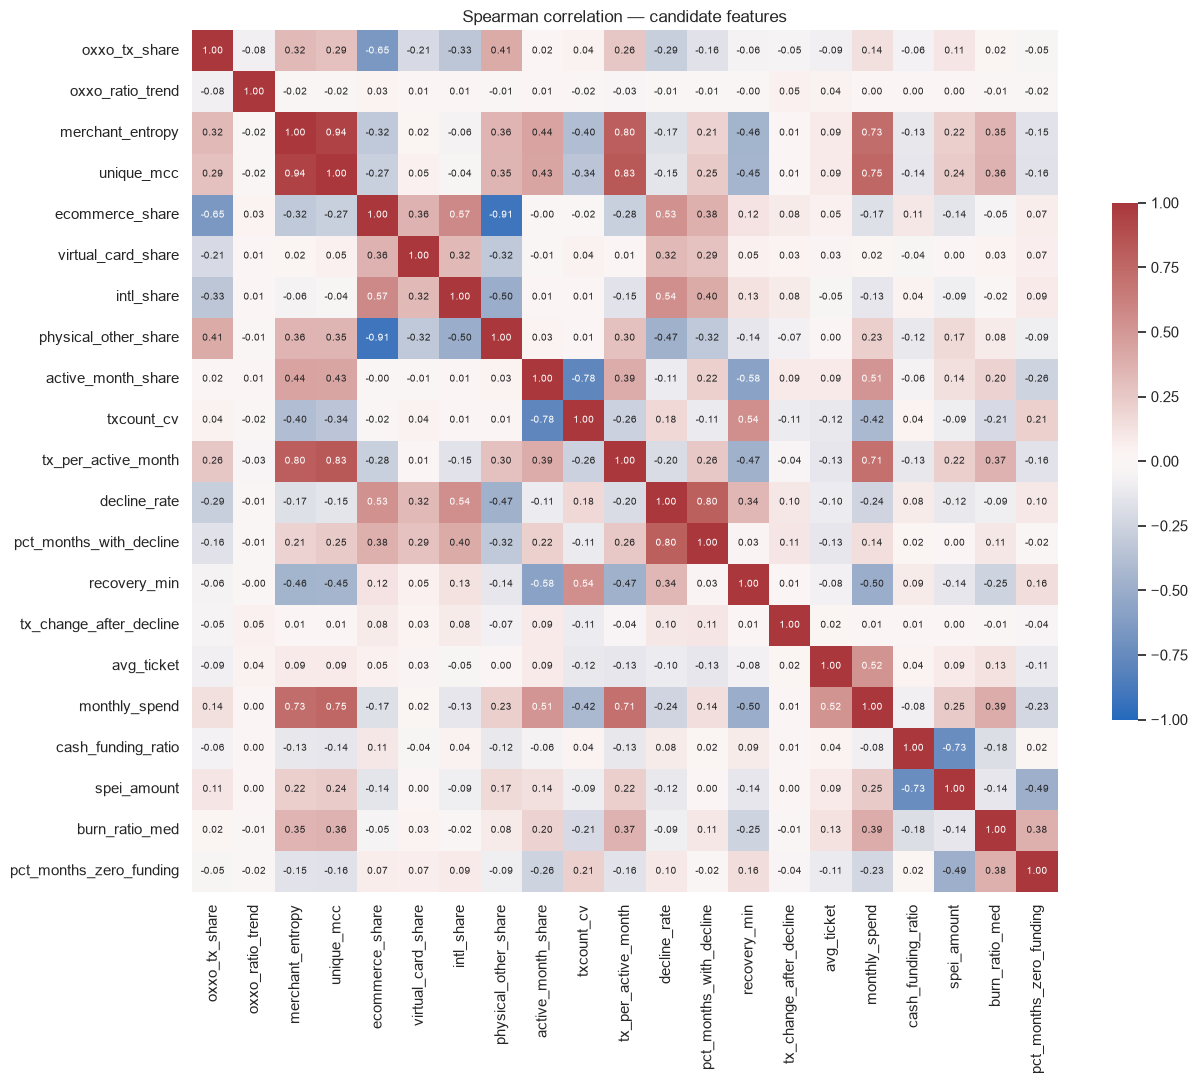

,a,b,spearman
0,merchant_entropy,unique_mcc,0.945
1,ecommerce_share,physical_other_share,-0.907
2,unique_mcc,tx_per_active_month,0.831
3,merchant_entropy,tx_per_active_month,0.799
4,decline_rate,pct_months_with_decline,0.797
5,active_month_share,txcount_cv,-0.776
6,unique_mcc,monthly_spend,0.751
7,cash_funding_ratio,spei_amount,-0.732
8,merchant_entropy,monthly_spend,0.725
9,tx_per_active_month,monthly_spend,0.706


In [7]:
corr = T[FEATS].corr("spearman")
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax, cbar_kws={"shrink": .6})
ax.set_title("Spearman correlation — candidate features"); plt.tight_layout(); plt.show()
pairs = sorted([(a, b, corr.loc[a, b]) for i, a in enumerate(FEATS) for b in FEATS[i + 1:] if abs(corr.loc[a, b]) >= .7], key=lambda t: -abs(t[2]))
pd.DataFrame(pairs, columns=["a", "b", "spearman"]).round(3)

In [8]:
# reduced set: for each |rho|>=0.7 pair drop the less interpretable member (priority list); drop no-information features
priority = ["oxxo_tx_share", "merchant_entropy", "ecommerce_share", "decline_rate", "txcount_cv", "monthly_spend", "virtual_card_share",
            "intl_share", "active_month_share", "cash_funding_ratio", "burn_ratio_med", "avg_ticket"]
drop = {f: "no information (>95% zeros)" for f in nzv.index}
for a, b, r in pairs:
    pa = priority.index(a) if a in priority else 99; pb = priority.index(b) if b in priority else 99
    lose, win = (b, a) if pa <= pb else (a, b)
    if lose not in drop and win not in drop: drop[lose] = f"|rho|={abs(r):.2f} with {win}"
KEEP = [f for f in FEATS if f not in drop]; print(len(KEEP), "kept:", KEEP); drop

14 kept: ['oxxo_tx_share', 'oxxo_ratio_trend', 'merchant_entropy', 'ecommerce_share', 'virtual_card_share', 'intl_share', 'txcount_cv', 'decline_rate', 'recovery_min', 'tx_change_after_decline', 'avg_ticket', 'cash_funding_ratio', 'burn_ratio_med', 'pct_months_zero_funding']


{'unique_mcc': '|rho|=0.94 with merchant_entropy',
 'physical_other_share': '|rho|=0.91 with ecommerce_share',
 'tx_per_active_month': '|rho|=0.80 with merchant_entropy',
 'pct_months_with_decline': '|rho|=0.80 with decline_rate',
 'active_month_share': '|rho|=0.78 with txcount_cv',
 'spei_amount': '|rho|=0.73 with cash_funding_ratio',
 'monthly_spend': '|rho|=0.73 with merchant_entropy'}

## 6. Feature readiness table

In [9]:
ready = pd.DataFrame({"Feature": FEATS,
    "% missing": [round(desc.loc[f, "pct_missing"], 2) for f in FEATS],
    "Skewness": [round(desc.loc[f, "skewness"], 2) for f in FEATS],
    "Transformation": [tname[f] + " + z-score" for f in FEATS],
    "Keep/Drop": ["Drop" if f in drop else "Keep" for f in FEATS],
    "Justification": [drop.get(f, f"signal for '{dim_of[f]}'; |rho|<0.7 vs other kept") for f in FEATS]})
ready

,Feature,% missing,Skewness,Transformation,Keep/Drop,Justification
0,oxxo_tx_share,0.00,2.53,winsorize P99 + log1p + z-score,Keep,signal for 'OXXO dependency'; |rho|<0.7 vs oth...
1,oxxo_ratio_trend,0.00,-0.32,none + z-score,Keep,signal for 'OXXO dependency'; |rho|<0.7 vs oth...
2,merchant_entropy,0.00,0.54,none + z-score,Keep,signal for 'Merchant diversity'; |rho|<0.7 vs ...
3,unique_mcc,0.00,1.79,winsorize P99 + log1p + z-score,Drop,|rho|=0.94 with merchant_entropy
4,ecommerce_share,0.00,0.06,none + z-score,Keep,signal for 'Channel & card mix'; |rho|<0.7 vs ...
5,virtual_card_share,0.00,2.16,winsorize P99 + log1p + z-score,Keep,signal for 'Channel & card mix'; |rho|<0.7 vs ...
6,intl_share,0.00,2.16,winsorize P99 + log1p + z-score,Keep,signal for 'Channel & card mix'; |rho|<0.7 vs ...
7,physical_other_share,0.00,0.25,none + z-score,Drop,|rho|=0.91 with ecommerce_share
8,active_month_share,0.00,-0.49,none + z-score,Drop,|rho|=0.78 with txcount_cv
9,txcount_cv,0.00,0.63,none + z-score,Keep,signal for 'Temporal habits (proxy)'; |rho|<0....


## 7. Is there natural group structure?

Hopkins statistic = 0.869   (0.5 = random, >0.75 = clear cluster tendency)


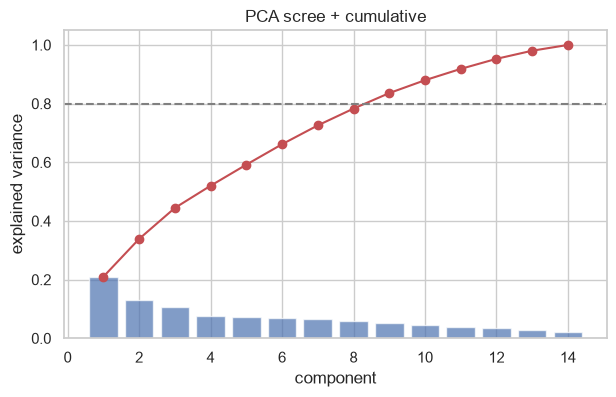

components for 80% variance: 9


In [10]:
Z = StandardScaler().fit_transform(T[KEEP])
def hopkins(X, m=1000):
    n, d = X.shape; nn = NearestNeighbors(n_neighbors=2).fit(X)
    u = nn.kneighbors(X[rng.choice(n, m, replace=False)], 2)[0][:, 1]
    w = nn.kneighbors(rng.uniform(X.min(0), X.max(0), (m, d)), 1)[0][:, 0]
    return w.sum() / (w.sum() + u.sum())
H = np.mean([hopkins(Z) for _ in range(10)])
print(f"Hopkins statistic = {H:.3f}   (0.5 = random, >0.75 = clear cluster tendency)")

pca = PCA().fit(Z); cum = np.cumsum(pca.explained_variance_ratio_); k = np.arange(1, len(cum) + 1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(k, pca.explained_variance_ratio_, alpha=.7); ax.plot(k, cum, "o-", color="#C44E52"); ax.axhline(.8, ls="--", c="grey")
ax.set_xlabel("component"); ax.set_ylabel("explained variance"); ax.set_title("PCA scree + cumulative"); plt.show()
print("components for 80% variance:", int(np.argmax(cum >= .8) + 1))

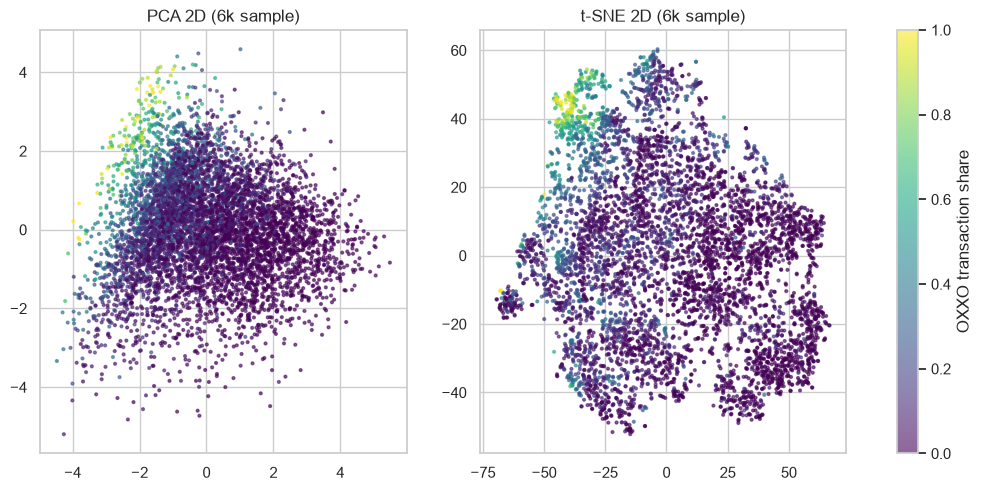

In [11]:
P = PCA(2).fit_transform(Z); idx = rng.choice(len(Z), 6000, replace=False)
TS = TSNE(2, perplexity=40, random_state=42, init="pca").fit_transform(Z[idx])
color = F["oxxo_tx_share"].values
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for a, XY, cc, t in [(ax[0], P[idx], color[idx], "PCA 2D (6k sample)"), (ax[1], TS, color[idx], "t-SNE 2D (6k sample)")]:
    sc = a.scatter(XY[:, 0], XY[:, 1], c=cc, s=4, cmap="viridis", alpha=.6); a.set_title(t)
plt.colorbar(sc, ax=ax, label="OXXO transaction share"); plt.show()

## 8. Distribution of OXXO share (concentration at 0/1, bimodality)

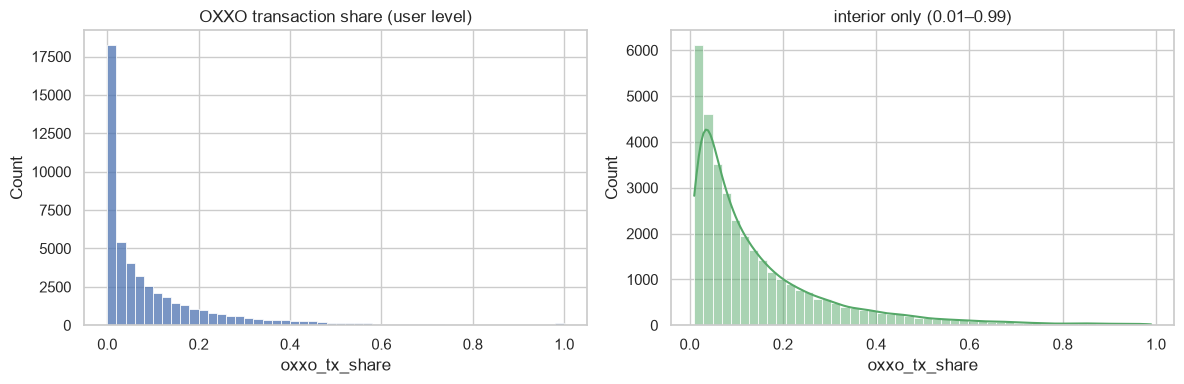

share <=1%: 30.0% | exactly 0: 25.8% | >=99%: 0.2% | exactly 1: 0.2% | >50%: 3.5%
bimodality coefficient: 0.687


In [12]:
o = F["oxxo_tx_share"].dropna()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(o, bins=50, ax=ax[0], color="#4C72B0"); ax[0].set_title("OXXO transaction share (user level)")
sns.histplot(o[(o > .01) & (o < .99)], bins=50, kde=True, ax=ax[1], color="#55A868"); ax[1].set_title("interior only (0.01–0.99)")
plt.tight_layout(); plt.show()
print(f"share <=1%: {(o<=.01).mean()*100:.1f}% | exactly 0: {(o==0).mean()*100:.1f}% | >=99%: {(o>=.99).mean()*100:.1f}% | exactly 1: {(o==1).mean()*100:.1f}% | >50%: {(o>.5).mean()*100:.1f}%")
# bimodality coefficient (>0.555 suggests bi/multimodal)
n_ = len(o); bc = (stats.skew(o)**2 + 1) / (stats.kurtosis(o) + 3 * (n_ - 1)**2 / ((n_ - 2) * (n_ - 3))); print("bimodality coefficient:", round(bc, 3))

## 9. Profiling by segment
Demographics (`accountLevel`, `creationFlowType`, age, gender, tenure) are **not in this file**. Substitute: *activity tier* = tertiles of average monthly spend, and *tenure proxy* = number of months observed.

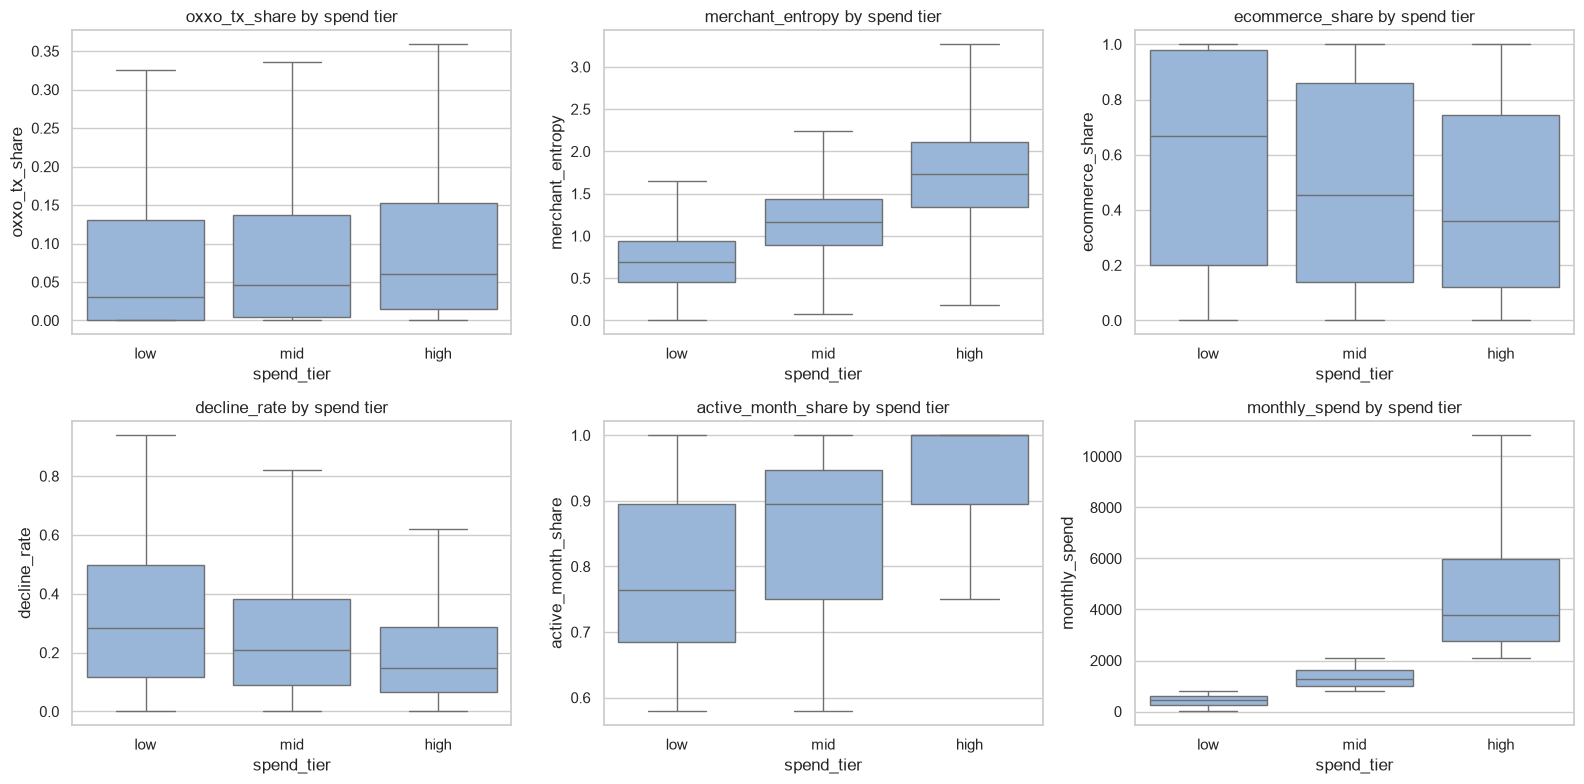

,oxxo_tx_share,merchant_entropy,ecommerce_share,decline_rate,active_month_share,monthly_spend
spend_tier,,,,,,
low,0.030,0.696,0.667,0.285,0.765,434.029
mid,0.046,1.164,0.453,0.210,0.895,1283.572
high,0.060,1.729,0.360,0.149,1.000,3773.711


,oxxo_tx_share,merchant_entropy,ecommerce_share,decline_rate,active_month_share,monthly_spend
tenure_band,,,,,,
<=12m,0.055,1.458,0.352,0.156,1.000,2047.548
13-18m,0.056,1.204,0.388,0.182,0.889,1343.568
19m,0.044,1.103,0.492,0.209,0.895,1257.928


In [13]:
F["spend_tier"] = pd.qcut(F["monthly_spend"], 3, labels=["low", "mid", "high"])
F["months_observed"] = df.groupby("userId").size()
F["tenure_band"] = pd.cut(F["months_observed"], [0, 12, 18, 19], labels=["<=12m", "13-18m", "19m"])
key = ["oxxo_tx_share", "merchant_entropy", "ecommerce_share", "decline_rate", "active_month_share", "monthly_spend"]
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for a, f in zip(ax.flat, key):
    sns.boxplot(data=F, x="spend_tier", y=f, ax=a, showfliers=False, color="#8EB4E3"); a.set_title(f"{f} by spend tier")
plt.tight_layout(); plt.show()
display(F.groupby("spend_tier", observed=True)[key].median().round(3)); display(F.groupby("tenure_band", observed=True)[key].median().round(3))

**Should segment variables be clustering inputs?** No — account level, creation flow, age, gender and tenure are *descriptors*, not behaviour.
Using them as inputs would make clusters recreate demographics (and tenure/spend tier mechanically drive activity features). Cluster on behaviour
only, then profile clusters against these variables afterwards. Requires the demographic columns from the master extract (join on `userId`).

## 10. Stability across periods
Because this is a real panel we can test the **same users** in two windows (first vs. last half of the observed months), not just population distributions.

In [14]:
mid = df.mes.min() + (df.mes.max() - df.mes.min()) / 2
Fa, Fb = user_features(df[df.mes <= mid]), user_features(df[df.mes > mid])
common = Fa.index.intersection(Fb.index); res = []
for f in KEEP:
    a, b = Fa.loc[common, f], Fb.loc[common, f]; m = a.notna() & b.notna()
    res.append(dict(feature=f, median_P1=a.median(), median_P2=b.median(), ks=stats.ks_2samp(a.dropna(), b.dropna()).statistic,
                    within_user_spearman=stats.spearmanr(a[m], b[m])[0]))
stab = pd.DataFrame(res).set_index("feature"); display(stab.round(3))
print(f"mean KS={stab.ks.mean():.3f}; mean within-user rank correlation={stab.within_user_spearman.mean():.2f}")
cA = Fa.loc[common, KEEP].fillna(Fa[KEEP].median()); cB = Fb.loc[common, KEEP].fillna(Fb[KEEP].median())
pa = PCA(3).fit(StandardScaler().fit_transform(cA)); pb = PCA(3).fit(StandardScaler().fit_transform(cB))
print("PCA loading cosine similarity P1 vs P2 (PC1-3):", [round(abs(float(pa.components_[i] @ pb.components_[i])), 3) for i in range(3)])

,median_P1,median_P2,ks,within_user_spearman
feature,,,,
oxxo_tx_share,0.045,0.031,0.055,0.693
oxxo_ratio_trend,0.000,0.000,0.023,-0.203
merchant_entropy,1.067,1.131,0.042,0.641
ecommerce_share,0.455,0.519,0.038,0.840
virtual_card_share,0.000,0.000,0.049,0.776
intl_share,0.020,0.023,0.017,0.680
txcount_cv,0.788,0.722,0.071,0.238
decline_rate,0.170,0.215,0.074,0.663
recovery_min,8169.670,7369.625,0.044,0.354


mean KS=0.048; mean within-user rank correlation=0.51
PCA loading cosine similarity P1 vs P2 (PC1-3): [0.984, 0.978, 0.952]


## 11. Conclusions
- **Feature set:** 28 → 14 behavioural features kept after the |ρ| ≥ 0.7 filter (entropy absorbs unique MCC, tx volume and spend; e-commerce share absorbs physical share; decline rate absorbs share of months with a decline). No feature was dropped for zero information.
- **Group structure:** Hopkins ≈ 0.87 (> 0.75) → clear cluster tendency; ~9 components are needed for 80% of the variance, so structure is multi-dimensional rather than one dominant axis.
- **OXXO share:** 25.8% of users have exactly 0 and ~30% ≤ 1%; only 0.2% sit at 1. It is a heavy spike at 0 with a long right tail (bimodality coefficient 0.69 > 0.555 reflects the spike + tail, not two interior modes) → model as zero-inflated: a 'never OXXO' flag + log-share.
- **Stability (same users, first vs. second half of the window):** distributions barely move (mean KS 0.05) and PCA loadings match (cosine 0.95–0.98), but individual rank persistence is mixed: high for e-commerce (0.84), virtual card (0.78), ticket (0.70), OXXO share (0.69); low for `txcount_cv` (0.24), `recovery_min` (0.35) and ≈ 0 / negative for `tx_change_after_decline` and `oxxo_ratio_trend`. Archetypes built on channel/OXXO/diversity should persist; those relying on friction-recovery or trend features would not.
- **Limits:** no demographics, payday/weekend/night or inter-transaction fields in this file, so those items need the master extract (see header).